In [1]:
print("hi")

hi


In [2]:
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
from typing import TypedDict, Literal, Annotated
import operator

from pydantic import BaseModel

In [4]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.types import Send
from langgraph.prebuilt import ToolNode

from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool

In [5]:
model = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)

In [6]:
def show_graph(compiled_graph):
   """print a generated mermaid with the graphviz mermaid syntax"""
   print(compiled_graph.get_graph().draw_mermaid())

In [7]:
# ============================================================
# 1. SEQUENTIAL WORKFLOW
# ============================================================

class ChainState(TypedDict):
    topic: str
    draft: str
    improved: str
    final: str


In [8]:
def generate(state: ChainState):
    response = model.invoke(
        f"Write a short explanation about {state['topic']}."
    )

    return {
        "draft": response.content
    }

In [9]:
def improve(state: ChainState):
    response = model.invoke(
        f"""
Improve this explanation and make it beginner friendly:

{state['draft']}
"""
    )

    return {
        "improved": response.content
    }

In [10]:
def polish(state: ChainState):
    response = model.invoke(
        f"""
Polish the following explanation.

Make it concise and clear:

{state['improved']}
"""
    )

    return {
        "final": response.content
    }

### 1.2 Build the sequential workflow graph

The nodes are connected sequentially from `START` to `END`.


In [11]:
def build_sequential_graph():
    builder = StateGraph(ChainState)

    builder.add_node("generate", generate)
    builder.add_node("improve", improve)
    builder.add_node("polish", polish)

    builder.add_edge(START, "generate")
    builder.add_edge("generate", "improve")
    builder.add_edge("improve", "polish")
    builder.add_edge("polish", END)

    return builder.compile()

In [12]:
sequential_graph = build_sequential_graph()

In [13]:
show_graph(sequential_graph)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	generate(generate)
	improve(improve)
	polish(polish)
	__end__([<p>__end__</p>]):::last
	__start__ --> generate;
	generate --> improve;
	improve --> polish;
	polish --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



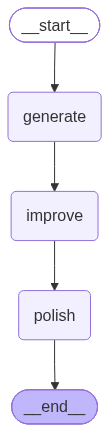

In [14]:
from IPython.display import Image, display

display(
    Image(
        sequential_graph.get_graph().draw_mermaid_png()
    )
)

In [15]:
def run_sequential_workflow(topic: str):
    print("\n" + "=" * 70)
    print("1. SEQUENTIAL WORKFLOW")
    print("=" * 70)

    graph = build_sequential_graph()

    result = graph.invoke(
        {
            "topic": topic
        }
    )

    print(
        result["final"]
    )

    return result

In [16]:
run_sequential_workflow("Retrieval-Augmented Generation")


1. SEQUENTIAL WORKFLOW
### Retrieval‑Augmented Generation (RAG)

A RAG system is a **smart assistant that looks up information while it talks**.  
It has two core components:

| Component | Role | Analogy |
|-----------|------|---------|
| **Retriever** | Scans a curated document set and returns the most relevant passages. | A librarian pulling the right pages. |
| **Generator** | A large language model that writes an answer, conditioned on the query and the retrieved passages. | A writer drafting a reply with the librarian’s notes. |

---

#### How it works

1. **Query** – You ask a question.  
2. **Retrieval** – The retriever searches the knowledge base (e.g., Wikipedia, company FAQs, custom docs) and returns a handful of passages.  
3. **Generation** – The language model receives the query + passages and produces an answer grounded in that evidence.  
4. **Result** – You get a factual, up‑to‑date response with reduced hallucination risk.

---

#### Why it matters

| Issue | RAG Adv

{'topic': 'Retrieval-Augmented Generation',
 'draft': '**Retrieval‑Augmented Generation (RAG)** is a hybrid language‑model technique that combines a large pretrained transformer (the “generator”) with an external knowledge source (the “retriever”).  \n1. **Retrieval step** – Given a user query, the system first searches a curated document collection (e.g., Wikipedia, a corporate knowledge base, or a custom dataset) and returns the most relevant passages.  \n2. **Generation step** – The retrieved passages are fed, along with the original query, into the language model, which conditions its output on both the prompt and the external evidence.  \n\nBy grounding responses in up‑to‑date, domain‑specific text, RAG reduces hallucinations, improves factual accuracy, and allows the model to stay current without retraining the entire network. It’s widely used in chatbots, question‑answering systems, and any application where reliable, context‑rich answers are critical.',
 'improved': '### What i

## 2. Parallelization — state


In [17]:
# ============================================================
# 2. PARALLELIZATION - FAN OUT / FAN IN
# ============================================================

class ParallelState(TypedDict):
    topic: str
    summary: str
    keywords: str
    questions: str
    final_output: str



In [18]:
def create_summary(state: ParallelState):
    response = model.invoke(
        f"Summarize {state['topic']}."
    )

    return {
        "summary": response.content
    }

In [19]:
def extract_keywords(state: ParallelState):
    response = model.invoke(
        f"Give 5 important keywords related to {state['topic']}."
    )

    return {
        "keywords": response.content
    }

In [20]:
def create_questions(state: ParallelState):
    response = model.invoke(
        f"Create 3 interview questions about {state['topic']}."
    )

    return {
        "questions": response.content
    }

In [21]:
def aggregate(state: ParallelState):
    final = f"""
    SUMMARY
    -------
    {state['summary']}

    KEYWORDS
    --------
    {state['keywords']}

    QUESTIONS
    ---------
    {state['questions']}
    """

    return {
        "final_output": final
    }

### 2.2 Build the fan-out/fan-in graph

In [22]:
def build_parallel_graph():
    builder = StateGraph(ParallelState)

    builder.add_node("summary", create_summary)
    builder.add_node("keywords", extract_keywords)
    builder.add_node("questions", create_questions)
    builder.add_node("aggregate", aggregate)

    # FAN OUT
    builder.add_edge(START, "summary")
    builder.add_edge(START, "keywords")
    builder.add_edge(START, "questions")

    # FAN IN
    builder.add_edge("summary", "aggregate")
    builder.add_edge("keywords", "aggregate")
    builder.add_edge("questions", "aggregate")

    builder.add_edge("aggregate", END)

    return builder.compile()


In [23]:
parallel_graph = build_parallel_graph()
show_graph(parallel_graph)


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	summary(summary)
	keywords(keywords)
	questions(questions)
	aggregate(aggregate)
	__end__([<p>__end__</p>]):::last
	__start__ --> keywords;
	__start__ --> questions;
	__start__ --> summary;
	keywords --> aggregate;
	questions --> aggregate;
	summary --> aggregate;
	aggregate --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



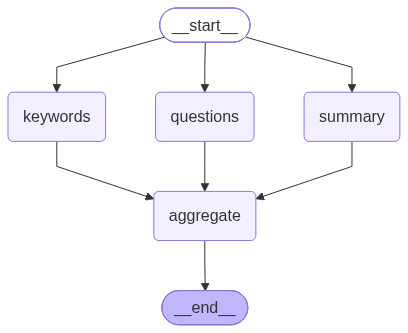

In [24]:
from IPython.display import Image, display

display(
    Image(
        parallel_graph.get_graph().draw_mermaid_png()
    )
)

In [25]:
def run_parallelization():
    print("\n" + "=" * 70)
    print("2. PARALLELIZATION - FAN OUT / FAN IN")
    print("=" * 70)

    graph = build_parallel_graph()

    result = graph.invoke(
        {
            "topic": "LangGraph"
        }
    )

    print(
        result["final_output"]
    )

    return result


In [26]:
run_parallelization()



2. PARALLELIZATION - FAN OUT / FAN IN

    SUMMARY
    -------
    **LangGraph – Quick Overview**

| What it is | A graph‑oriented framework for building LLM‑powered applications. It lets you design, execute, and debug complex, multi‑step workflows that involve language models, external tools, and stateful logic. |
|------------|---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Core idea | Treat every step in an LLM workflow as a *node* in a directed graph. Nodes can be prompts, tool calls, or custom logic. Edges define the flow, allowing branching, loops, and dynamic re‑routing based on runtime data. |
| Key components | • **Nodes** – functions that produce output (e.g., a prompt, a tool invocation, or a Python function).<br>• **Edges** – connections that decide the next node based on the current state.<br>• **State** – a dictionary that

{'topic': 'LangGraph',
 'summary': '**LangGraph – Quick Overview**\n\n| What it is | A graph‑oriented framework for building LLM‑powered applications. It lets you design, execute, and debug complex, multi‑step workflows that involve language models, external tools, and stateful logic. |\n|------------|---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|\n| Core idea | Treat every step in an LLM workflow as a *node* in a directed graph. Nodes can be prompts, tool calls, or custom logic. Edges define the flow, allowing branching, loops, and dynamic re‑routing based on runtime data. |\n| Key components | • **Nodes** – functions that produce output (e.g., a prompt, a tool invocation, or a Python function).<br>• **Edges** – connections that decide the next node based on the current state.<br>• **State** – a dictionary that carries context, memory, a